# Is a topology-optimised part a CAD model? Checking the quality of a skin-to-CAD solid

`hook.mdpa` is a Kratos topology-optimisation result: a hook as a tetrahedral mesh
(39,292 nodes, 197,541 tetrahedra), with its load and support surfaces as boundary
conditions (16,081 triangles). An optimiser carves such a part out of a block, so its
surface is the iso-surface of a density field rather than a set of designed faces.

The question this notebook asks is whether the skin of that part can be turned into a
CAD model worth handing to a designer, and how to check that it was. "Quality" here is
four things, each measured below:

- **the skin is a closed surface** that a solid can be built from;
- **the surface is explained by primitives**: how many patches a plane, cylinder, cone,
  sphere or torus fits, and within what tolerance;
- **the solid is valid and accurate**: OpenCASCADE's B-rep check, its volume against the
  skin's, and the largest distance between the two;
- **the faces are CAD faces**: how many are analytic surfaces, and how many are facets
  a designer would have to clean up.

In [1]:
import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv

os.environ.setdefault('MESHIOPLUSPLUS_LOG_LEVEL', 'error')
os.environ.setdefault('VTK_DEFAULT_OPENGL_WINDOW', 'vtkEGLRenderWindow')  # no X server
import meshioplusplus as mp  # noqa: E402
from meshioplusplus._fit_cad import has_occt  # noqa: E402

# Head-less, static rendering (no display / live server needed).
pv.OFF_SCREEN = True
pv.set_jupyter_backend('static')
TMP = tempfile.mkdtemp()
DATA = os.path.join(os.path.dirname(os.getcwd()), 'data', 'hook.mdpa')
TYPES = ['none', 'plane', 'sphere', 'cylinder', 'cone', 'torus']
TYPE_COLORS = ['#888888', '#4c78a8', '#f58518', '#54a24b', '#e45756', '#b279a2']


def to_grid(mesh):
    '''A PyVista grid of a meshio++ mesh, through a temporary .vtu.'''
    target = os.path.join(TMP, 'render.vtu')
    mp.write(target, mesh)
    return pv.read(target)


def render(mesh, title, scalars=None, cmap='tab10', clim=None, annotations=None,
           view=(1.0, -1.6, 0.9)):
    '''Render with PyVista, or the points with matplotlib when GL is unavailable.'''
    fig, ax = plt.subplots(figsize=(9, 6))
    try:
        grid = to_grid(mesh)
        pl = pv.Plotter(off_screen=True, window_size=(1000, 720))
        kwargs = {'show_edges': False}
        if scalars is not None:
            bar = {'title': scalars, 'vertical': True, 'position_x': 0.86,
                   'position_y': 0.15, 'height': 0.7, 'width': 0.06}
            if annotations:
                bar['n_labels'] = 0
            kwargs.update(scalars=scalars, cmap=cmap, clim=clim, categories=True,
                          annotations=annotations, scalar_bar_args=bar)
        else:
            kwargs['color'] = '#2ec4b6'
        pl.add_mesh(grid, **kwargs)
        pl.view_vector(view, viewup=(0, 0, 1))
        pl.reset_camera()
        pl.camera.zoom(1.15)
        img = pl.screenshot(return_img=True)
        pl.close()
        ax.imshow(img)
    except Exception as exc:  # pragma: no cover - head-less GL fallback
        print('PyVista render skipped:', exc)
        p = np.asarray(mesh.points)
        ax.scatter(p[:, 0], p[:, 2], s=1)
    ax.set_title(title)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

## Read the part and take its skin

The reader keeps the tetrahedra and the boundary conditions; the skin is the surface of
the tetrahedra. `feature_edges` counts what would stop a solid being built from it:
open edges, non-manifold edges and inconsistently wound ones. The creases are the edges
between faces that meet at more than 30 degrees.

In [2]:
part = mp.read(DATA)
print(f"{part.points.shape[0]:,} nodes, " + ", ".join(f"{len(c.data):,} {c.type}" for c in part.cells))

skin = mp.extract_skin(part)
pts = np.asarray(skin.points)
diag = float(np.linalg.norm(pts.max(axis=0) - pts.min(axis=0)))
print(f"skin: {len(skin.cells[0].data):,} triangles on {len(pts):,} points, diagonal {diag:.1f}")

_, edges = mp.feature_edges(skin, return_report=True)
print("open {num_boundary}, non-manifold {num_non_manifold}, inconsistent {num_inconsistent}, "
      "creases {num_feature}".format(**edges))

39,292 nodes, 197,541 tetra, 16,081 triangle


skin: 22,236 triangles on 11,120 points, diagonal 271.9
open 0, non-manifold 0, inconsistent 0, creases 295


## Segment the surface by primitives

`method="primitive"` ends a patch where the surface its facets lie on changes: a region
grows while one plane, cylinder, cone, sphere or torus explains it within the tolerance,
which is 0.1 % of the diagonal by default. The angle-based segmentation that `segment`
uses otherwise has no such test.

{'num_patches': 6, 'num_merged': 0, 'num_feature_edges': 295, 'num_boundary_edges': 0, 'num_non_manifold_edges': 0}


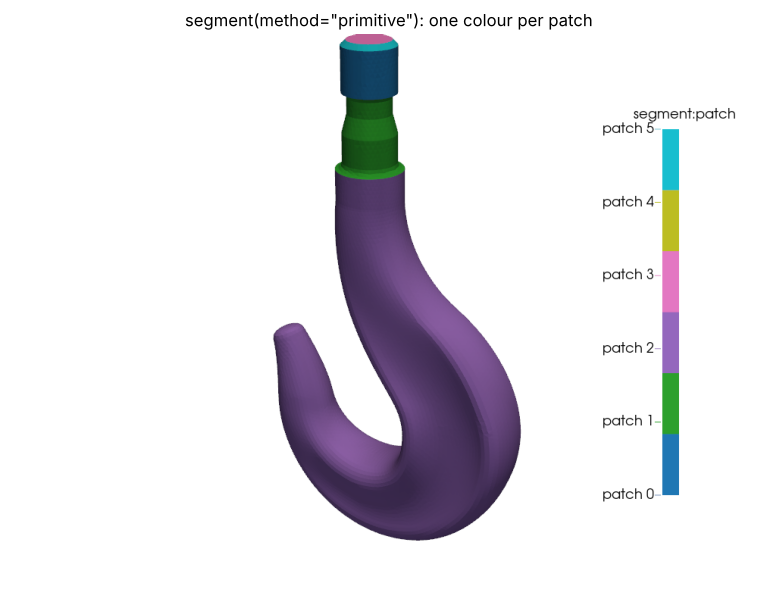

In [3]:
seg, seg_report = mp.segment(skin, method='primitive', return_report=True)
print(seg_report)
patches = {k: f'patch {k}' for k in range(seg_report['num_patches'])}
render(seg, 'segment(method="primitive"): one colour per patch', scalars='segment:patch',
       annotations=patches)

## Fit a primitive to each patch

Each patch is fitted with every primitive, and the simplest one within the tolerance is
kept. A patch that none fits is reported as `none` with its best residual, and is left
for the freeform fit below.

patch      type  facets        rms
    0  cylinder     950     0.0000
    1      none   1,645     0.6665
    2      none  19,243     8.1140
    3     plane     130     0.0000
    4      cone     190     0.0417
    5      cone      78     0.0000


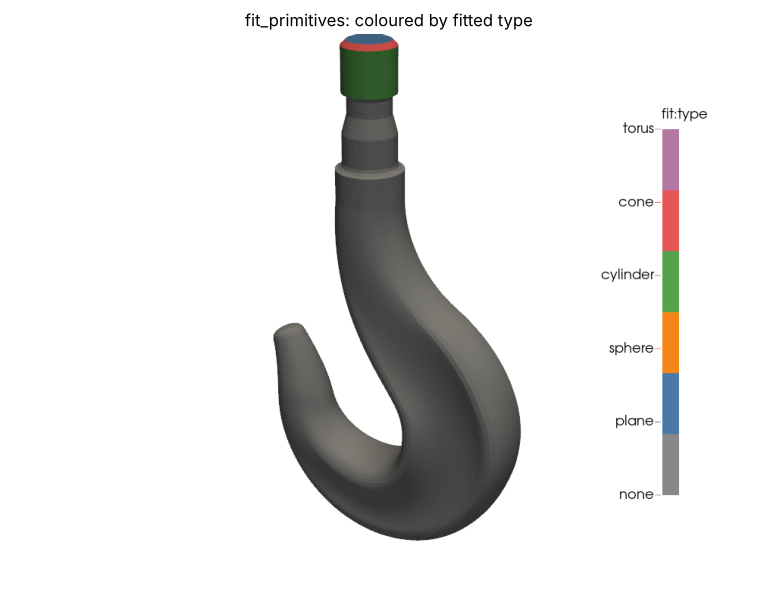

In [4]:
fit, fit_report = mp.fit_primitives(seg, tolerance=1e-3 * diag, relative=False,
                                    return_report=True)
fd = fit.field_data
cells = np.bincount(np.concatenate(fit.cell_data['segment:patch']))
print(f"{'patch':>5} {'type':>9} {'facets':>7} {'rms':>10}")
for pid, t, rms in zip(fd['fit:patch_id'], fd['fit:patch_type'], fd['fit:patch_rms']):
    print(f"{pid:>5} {TYPES[t]:>9} {cells[pid]:>7,} {rms:>10.4f}")
render(fit, 'fit_primitives: coloured by fitted type', scalars='fit:type',
       cmap=TYPE_COLORS, clim=[0, 5], annotations={i: TYPES[i] for i in range(6)})

## Build the CAD solid

`fit_cad` makes each fitted patch an analytic face, tries the patches no primitive
explains as freeform B-spline faces (a patch no single B-spline follows is halved across its
longest extent, and each half is fitted in turn, up to nine times, as a tile), sews the faces into a solid, and checks it. A face
that fails the check, or strays further than the tolerance from the skin, is demoted
to facets, so the solid is always valid. With OpenCASCADE this run takes about five
minutes; without it, `fit_cad` uses its kernel-free native backend, which writes the
analytic faces only.

backend occt: valid True, 1 solid(s)
volume 308054.1 of the skin, 308263.7 of the solid (ratio 1.00068)
largest distance from the skin 0.699 (tolerance 0.816)
faces: 8,714 in all; 39 analytic (plane 1, cylinder 1, cone 2, sphere 0, torus 0), 35 freeform, 8,675 facets; 25 patch(es) demoted


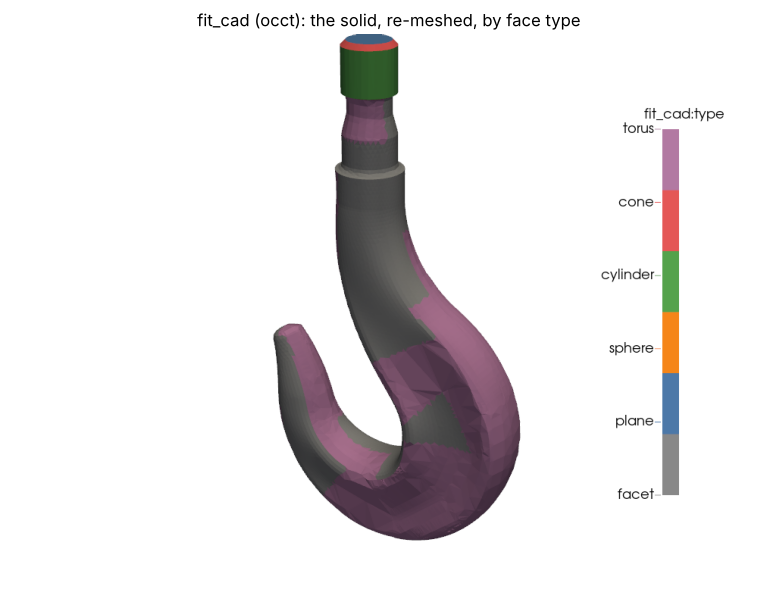

In [5]:
path = os.path.join(TMP, 'hook_cad.step')
solid, cad = mp.fit_cad(fit, path, return_report=True)
faces = cad['num_faces']
analytic = faces - cad['num_faceted_faces']
print(f"backend {cad['backend']}: valid {cad['valid']}, {cad['num_solids']} solid(s)")
print(f"volume {cad['skin_volume']:.1f} of the skin, {cad['volume']:.1f} of the solid "
      f"(ratio {cad['volume_ratio']:.5f})")
print(f"largest distance from the skin {cad['max_deviation']:.3f} "
      f"(tolerance {cad['tolerance']:.3f})")
print(f"faces: {faces:,} in all; {analytic:,} analytic (plane {cad['num_plane']}, "
      f"cylinder {cad['num_cylinder']}, cone {cad['num_cone']}, sphere {cad['num_sphere']}, "
      f"torus {cad['num_torus']}), {cad['num_bspline']} freeform, "
      f"{cad['num_faceted_faces']:,} facets; {cad['num_demoted']} patch(es) demoted")
render(solid, f"fit_cad ({cad['backend']}): the solid, re-meshed, by face type",
       scalars='fit_cad:type', cmap=TYPE_COLORS, clim=[0, 5],
       annotations={0: 'facet', **{i: TYPES[i] for i in range(1, 6)}})

The skin is closed, with no open or non-manifold edges, and the solid built from it passes the B-rep check. Its volume is within 0.07 % of the skin's, and its largest distance from the skin, 0.699, is inside the tolerance of 0.816. The geometry is faithful.

It is a much smaller model than the skin, though still not a clean CAD model. Of 8,714 faces, 39 are analytic (a plane, a cylinder and two cones) and 35 are freeform B-splines; the other 8,675 are facets. The six patches split as four that a primitive explains and two that none does, holding 94 % of the skin's triangles. No single B-spline follows either of those two within the tolerance, so `fit_cad` halves each across its longest extent and fits the halves in turn, as tiles; the tiles that a B-spline follows become freeform faces, which replaces thousands of facets, and the rest, where the surface is detailed at the scale of its mesh, stay faceted. 25 patches were demoted to facets by the validity and deviation checks. `MESHIOPLUSPLUS_LOG_LEVEL=debug` prints each rejected fit with its residual. Before the tiling the same part came out as 20,892 faces, 4 of them analytic and none freeform.

That is the honest result for this part. A topology-optimised surface is the iso-surface of a density field, not a set of smooth faces. The solid is valid and accurate, and far less faceted than before, but a designer would still smooth or re-model the remaining facets before using it as CAD.


In [6]:
share = (cad['num_faces'] - cad['num_faceted_faces']) / cad['num_faces']
print(f"geometry: volume within {abs(cad['volume_ratio'] - 1) * 100:.3f} % of the skin, "
      f"deviation within tolerance: {cad['max_deviation'] <= cad['tolerance']}")
print(f"topology: B-rep valid: {cad['valid']}")
print(f"CAD-likeness: {share * 100:.2f} % of the faces are analytic surfaces")

geometry: volume within 0.068 % of the skin, deviation within tolerance: True
topology: B-rep valid: True
CAD-likeness: 0.45 % of the faces are analytic surfaces
